## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** — клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics — PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [1]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7443k  100 7443k    0     0  2632k      0  0:00:02  0:00:02 --:--:-- 2632k


In [2]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

In [3]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [4]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [5]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [6]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [7]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [8]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='str')

# Какие есть ещё поля в AnnData? 

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** — клетки (observations).
- **Столбцы** — гены (variables).
- **Элементы** — значения экспрессии генов в клетках.

Здесь `adata.X` — название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ — количества столбцов с метаданными, а $d$ — число измерений в многомерном представлении.

In [9]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [10]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

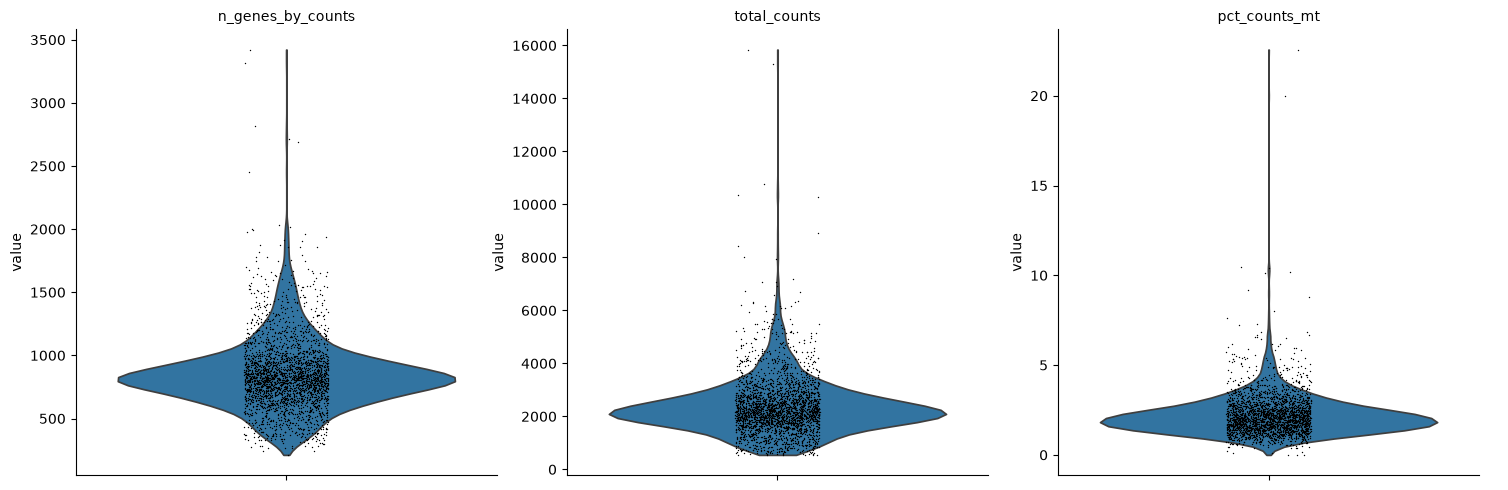

In [11]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [12]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [13]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [14]:
adata.layers["counts"] = adata.X.copy()

In [15]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X), 'counts'

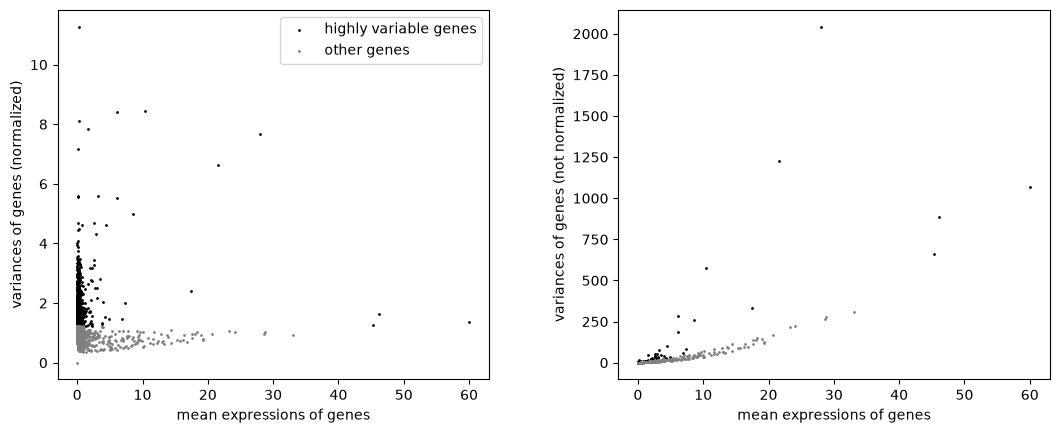

In [16]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [17]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: None (.X), 'counts'

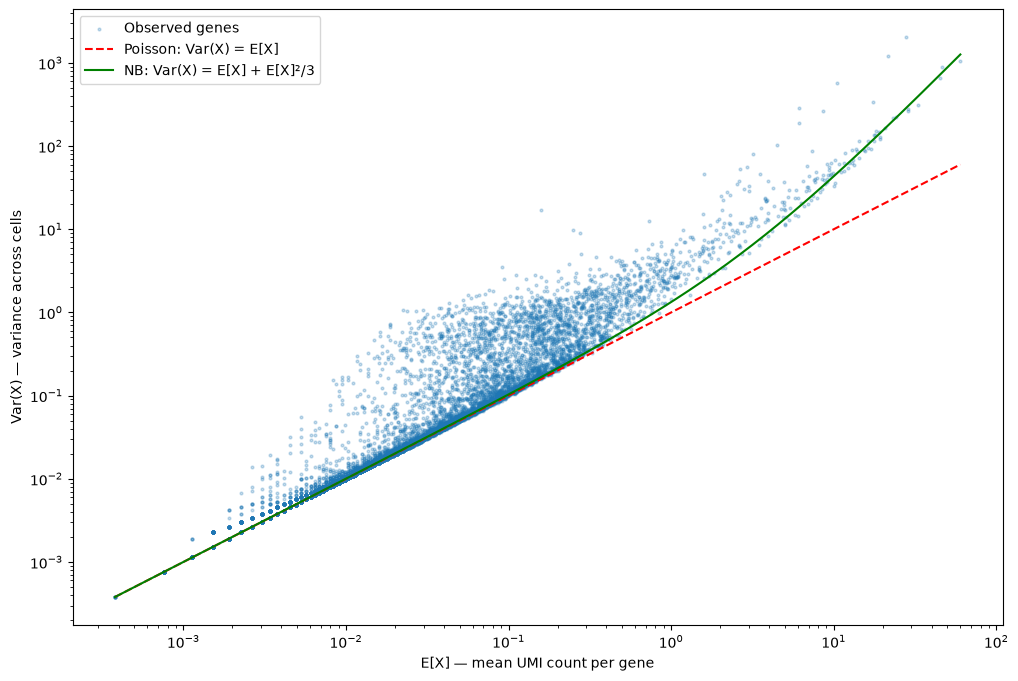

In [18]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] — mean UMI count per gene")
plt.ylabel("Var(X) — variance across cells")
plt.legend()
plt.show()

In [19]:
sc.pp.normalize_total(adata, target_sum=1e4) # учитываем разный размер библиотеки. Нормализуем на глубину секвенирования
sc.pp.log1p(adata) # уменьшаем влияние сильно экспрессируемых генов

In [20]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: None (.X), 'counts'

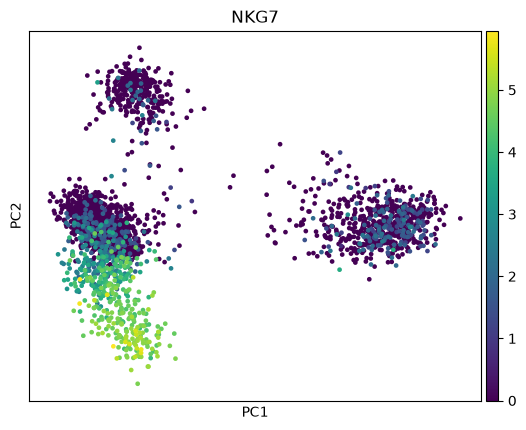

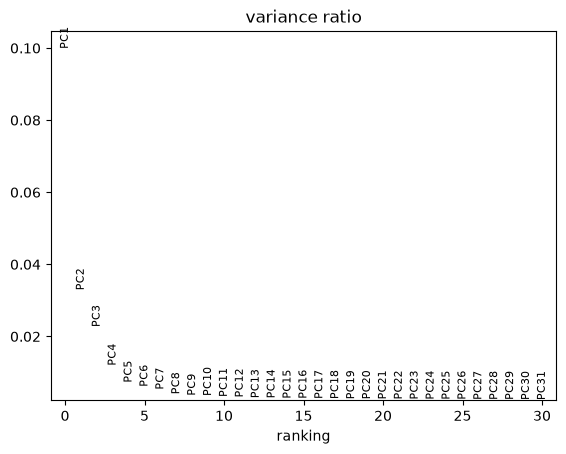

In [21]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [22]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

### Рабочая копия для следующих заданий

Дальше мы будем пробовать разные варианты QC, HVG и нормализации. Чтобы не трогать
основной `adata` из занятия и всегда иметь возможность вернуться к одному и тому же
отправному состоянию (QC-фильтрация → `layers["counts"]` → HVG `seurat_v3` →
`normalize_total` + `log1p` → PCA), сохраним его копию в `adata_base`. Именно
`adata_base` будет использоваться как отправная точка в заданиях 2, 4, 6 и в
дополнительном задании (там, где по умолчанию нужен анализ "с QC-фильтрацией и PCA
по HVG").

In [23]:
adata_base = adata.copy()
adata_base

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

## Подумайте 

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?
* По каким генам можно ещё делать QC?   
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?
* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

### Ответы

In [24]:
print("Ключи в adata.layers:", list(adata.layers.keys()))
adata.layers["counts"]

Ключи в adata.layers: [None, 'counts']


<Compressed Sparse Column sparse matrix of dtype 'float32'
	with 2238732 stored elements and shape (2638, 13714)>

- **Что в слоях adata и что это такое?** После занятия в `adata.layers` лежит
  `"counts"` — это "замороженная" копия сырых (целочисленных) UMI-counts,
  сохранённая сразу после QC-фильтрации, но до `normalize_total`/`log1p`. Сам
  `adata.X` при этом уже содержит нормализованную и прологарифмированную матрицу.
  Слои нужны именно для этого: продолжать работать с нормализованными данными в
  `X` (PCA, кластеризация, визуализация), но не терять доступ к исходным counts —
  они нужны, например, для `flavor="seurat_v3"` при отборе HVG или для
  дифференциальной экспрессии с моделями, рассчитанными на счётчиках.
- **По каким ещё генам можно делать QC?** Кроме митохондриальных генов часто
  используют: рибосомные белки (`RPS*`/`RPL*`) — резкий рост их доли может быть
  артефактом; гены гемоглобина (`HBB`, `HBA1/2` и т.п.) — признак примеси
  эритроцитов/их фрагментов; специфичные для пола гены (`XIST`, гены Y-хромосомы)
  — для проверки, что образец не перепутан и не является смесью доноров; гены
  теплового шока (`HSPA1A/B` и др.) — признак стресса клеток при диссоциации
  ткани. Эти группы и используются в задании 1.
- **Поиск по именам генов или по gtf/gff?** Надёжнее — по аннотации (gtf/gff),
  где у каждого гена явно указаны хромосома/биотип: так можно без ошибок выбрать
  именно митохондриальные гены (по хромосоме `MT`/`chrM`), не полагаясь на то,
  что имя гена начинается с конкретного префикса. Поиск по префиксу имени (как
  `str.startswith("MT-")`) — это удобный, но хрупкий способ: он зависит от
  конкретной номенклатуры генов и может как случайно включить лишние гены, так и
  пропустить часть нужных, если аннотация имён неполная или нестандартная.
- **Сколько генов на митохондриальной хромосоме и все ли они начинаются с MT?** У
  человека на мтДНК аннотировано 37 генов: 13 белок-кодирующих, 22 тРНК и 2 рРНК.
  В современной номенклатуре HGNC все они официально называются с префиксом
  `MT-` (`MT-ND1`, `MT-CO1`, `MT-CYB`, `MT-RNR1/2`, `MT-T*` и т.д.), поэтому по
  актуальной аннотации — да, все 37. Но в старых версиях аннотаций, у части
  провайдеров и в разных форматах файлов (символ гена vs ID) написание может
  отличаться, так что полагаться только на текстовый префикс стоит с
  осторожностью.
- **Как называются митохондриальные гены у других организмов?** У коровы (Bos
  taurus), собаки (Canis familiaris), лошади, кошки, свиньи и приматов (например,
  шимпанзе) используется та же, "человеческая" номенклатура VGNC — префикс
  `MT-` (заглавными буквами), как и у человека. А вот у мыши (Mus musculus) и
  крысы (Rattus norvegicus) принята нотация с префиксом `mt-`/`Mt-` (строчными,
  как и для большинства генов грызунов). Поэтому при работе с данными мыши
  фильтр `str.startswith("MT-")` работать не будет — нужен `str.startswith("mt-")`.

**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили. 

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X — значение QC-метрики;
   - Y — количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


### Решение

In [25]:
# Загружаем данные заново, БЕЗ фильтрации — чтобы увидеть распределения QC-метрик
# на всех клетках, включая потенциально "плохие". Именно по таким графикам
# обычно и подбирают пороги фильтрации, поэтому логично смотреть на них до неё.
adata_full = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

adata_full.var["mt"] = adata_full.var_names.str.startswith("MT-")
# рибосомные белки: в норме могут быть экспрессированы очень сильно,
# резкие выбросы — повод присмотреться к клетке
adata_full.var["ribo"] = adata_full.var_names.str.startswith(("RPS", "RPL"))
# гемоглобин: высокая доля — признак примеси эритроцитов/их фрагментов
adata_full.var["hb"] = adata_full.var_names.str.contains(r"^HB[^(P)]", regex=True)

print("Митохондриальных генов:", adata_full.var["mt"].sum())
print("Рибосомных генов:", adata_full.var["ribo"].sum())
print("Генов гемоглобина:", adata_full.var["hb"].sum())

Митохондриальных генов: 13
Рибосомных генов: 106
Генов гемоглобина: 13


In [26]:
sc.pp.calculate_qc_metrics(
    adata_full, qc_vars=["mt", "ribo", "hb"], percent_top=None, inplace=True
)
adata_full.obs.head()

,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,total_counts_ribo,log1p_total_counts_ribo,pct_counts_ribo,total_counts_hb,log1p_total_counts_hb,pct_counts_hb
AAACATACAACCAC-1,781,6.661855,2421.0,7.792349,73.0,4.304065,3.015283,1057.0,6.964136,43.659645,0.0,0.0,0.0
AAACATTGAGCTAC-1,1352,7.210080,4903.0,8.497807,186.0,5.231109,3.793596,2079.0,7.640123,42.402611,0.0,0.0,0.0
AAACATTGATCAGC-1,1131,7.031741,3149.0,8.055158,28.0,3.367296,0.889171,997.0,6.905753,31.660847,0.0,0.0,0.0
AAACCGTGCTTCCG-1,960,6.867974,2639.0,7.878534,46.0,3.850147,1.743085,640.0,6.463029,24.251610,0.0,0.0,0.0
AAACCGTGTATGCG-1,522,6.259581,981.0,6.889591,12.0,2.564949,1.223242,146.0,4.990433,14.882773,0.0,0.0,0.0


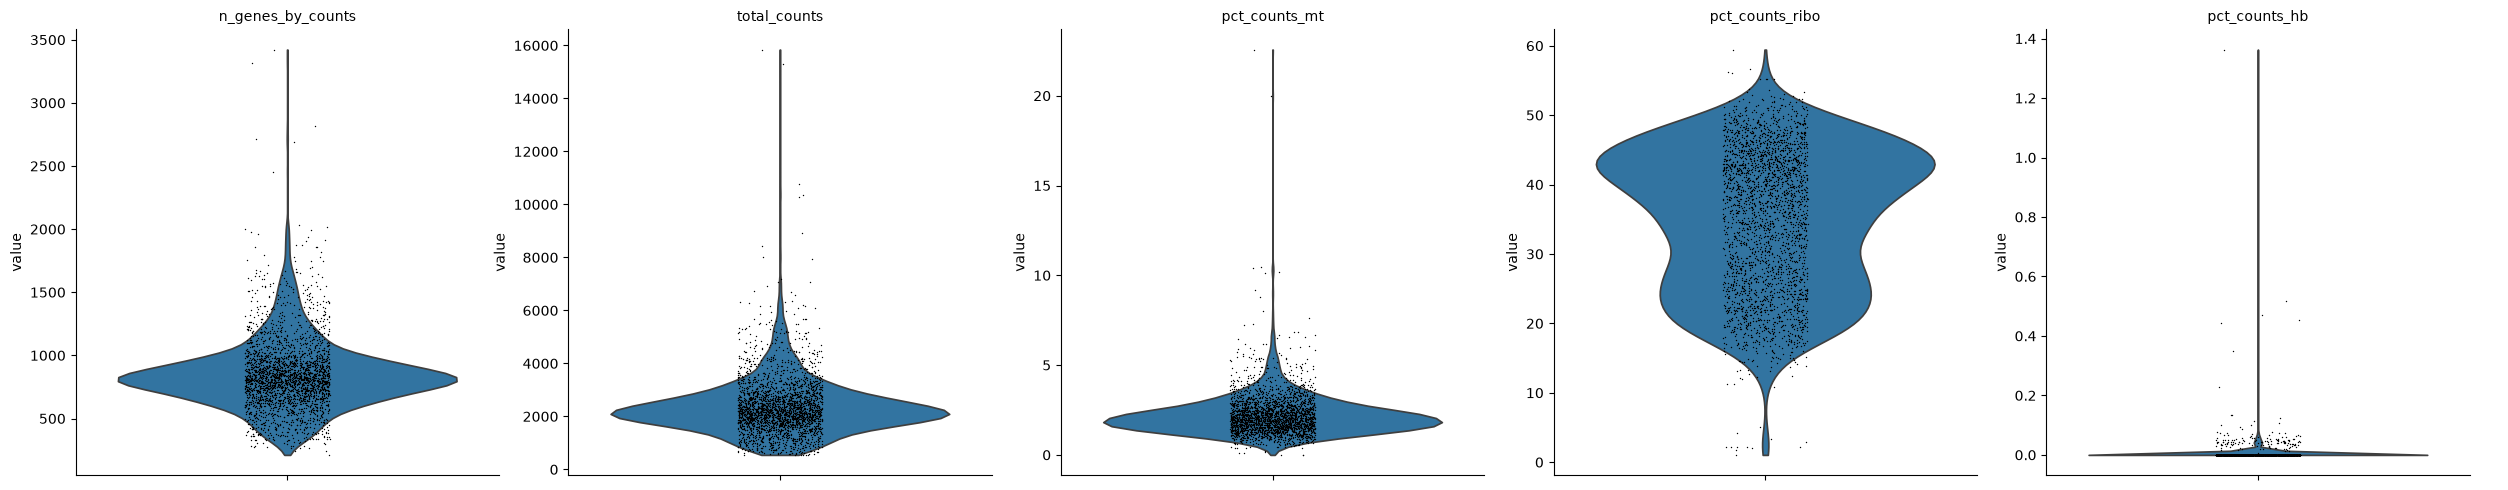

In [27]:
qc_metrics = [
    "n_genes_by_counts",
    "total_counts",
    "pct_counts_mt",
    "pct_counts_ribo",
    "pct_counts_hb",
]

# 1. Violin plot по всем QC-метрикам
sc.pl.violin(adata_full, qc_metrics, multi_panel=True)

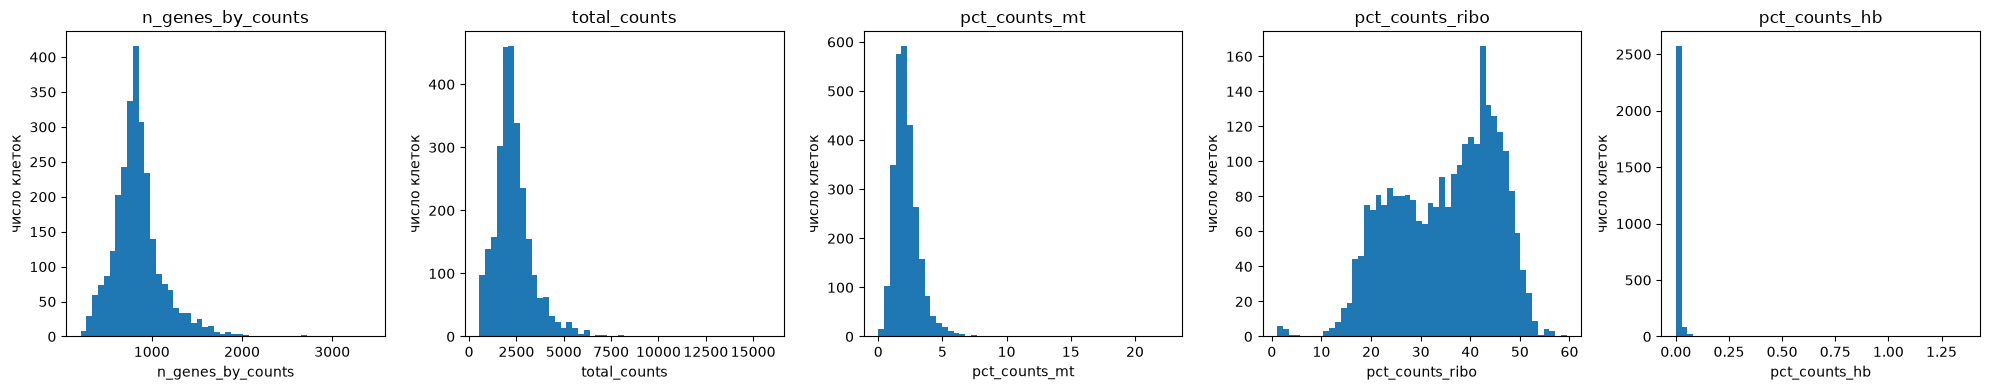

In [28]:
# 2. Гистограммы распределения каждой метрики
fig, axes = plt.subplots(1, len(qc_metrics), figsize=(4 * len(qc_metrics), 4))
for ax, metric in zip(axes, qc_metrics):
    ax.hist(adata_full.obs[metric], bins=50)
    ax.set_xlabel(metric)
    ax.set_ylabel("число клеток")
    ax.set_title(metric)
plt.tight_layout()
plt.show()

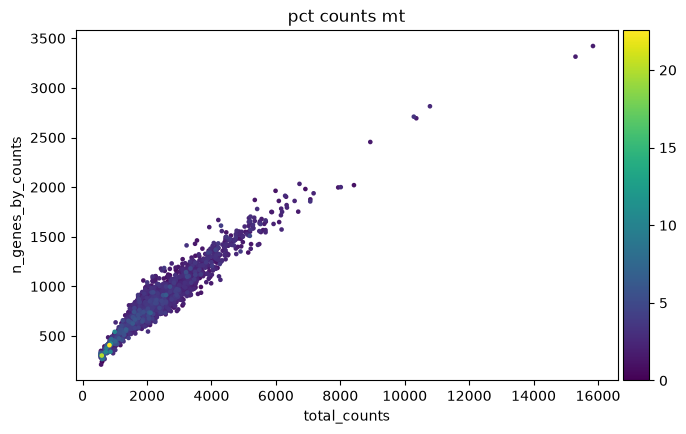

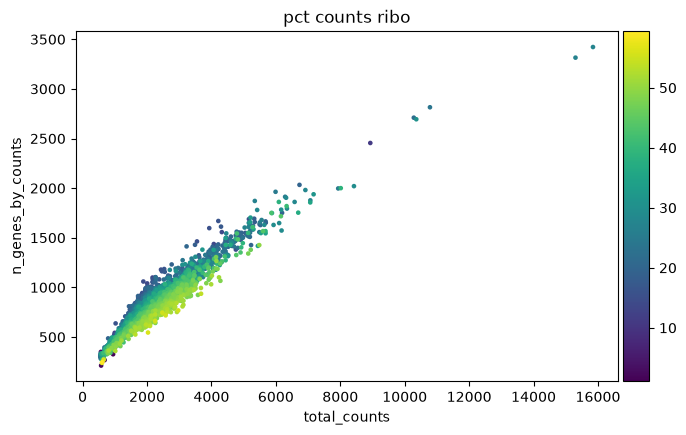

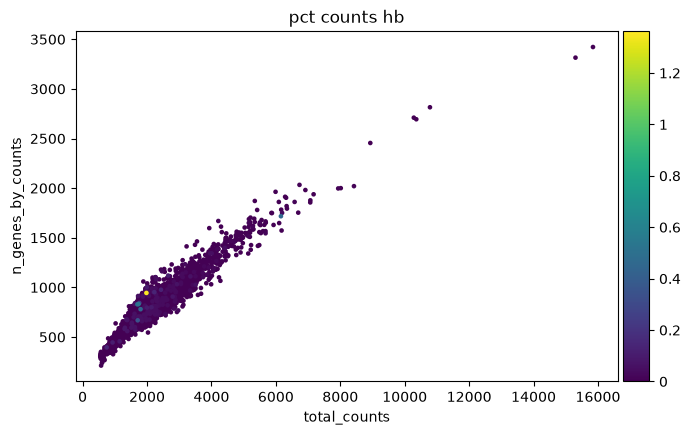

In [29]:
# 3. Scatter: число обнаруженных генов vs общее число UMI, окраска по доле мито-UMI
sc.pl.scatter(
    adata_full, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt"
)

# дополнительно окрасим тем же графиком по доле рибосомных и гемоглобиновых UMI —
# это помогает отдельно увидеть вклад каждой группы генов
sc.pl.scatter(
    adata_full, x="total_counts", y="n_genes_by_counts", color="pct_counts_ribo"
)
sc.pl.scatter(
    adata_full, x="total_counts", y="n_genes_by_counts", color="pct_counts_hb"
)

**Ответы.**

Подозрительны прежде всего клетки с *одновременно* малым числом UMI/генов и
повышенной долей митохондриальных транскриптов — это типичная картина
лизированных/умирающих клеток, у которых цитоплазматическая мРНК потеряна, а
относительно устойчивые митохондриальные транскрипты остались. Также
подозрительны клетки-выбросы с аномально большим `total_counts`/`n_genes` при
типичной глубине секвенирования остальных клеток — это кандидаты в дублеты
(два слипшихся дроплета дают вдвое больше UMI и генов).

О низком качестве клетки обычно говорят: малое число генов/UMI (мало
транскриптов захвачено в дроплет), высокая `pct_counts_mt` (повреждена мембрана,
цитоплазматическая РНК "вытекла", остались только защищённые митохондриальные
транскрипты), а иногда и высокая `pct_counts_hb` (клетка — на самом деле
загрязнение эритроцитами/их обломками, а не настоящая иммунная клетка).

Высокая доля определённой группы генов не всегда означает плохое качество,
потому что некоторые типы клеток *в норме* сильно экспрессируют
соответствующие гены: например, у активно секретирующих/делящихся клеток
(в PBMC — например, у части активированных лимфоцитов или плазматических
клеток) физиологически высокая доля рибосомных транскрипов — просто потому что
они активно синтезируют белок, а не потому что клетка повреждена. Поэтому
QC-метрики нужно интерпретировать не по одной, а в комбинации друг с другом.

## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`. 

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


### Решение

In [30]:
marker_genes = ["CD3D", "MS4A1", "NKG7", "LST1"]  # T, B, NK, Моноциты
n_top_genes = 2000

# Метод 1: seurat_v3 — уже посчитан в основном пайплайне занятия
adata_v3 = adata_base.copy()
hvg_v3 = set(adata_v3.var_names[adata_v3.var["highly_variable"]])

# Метод 2: seurat — дисперсионный метод, работает на нормализованной и
# прологарифмированной матрице (то есть на adata.X)
adata_seurat = adata_base.copy()
sc.pp.highly_variable_genes(adata_seurat, flavor="seurat", n_top_genes=n_top_genes)
hvg_seurat = set(adata_seurat.var_names[adata_seurat.var["highly_variable"]])

# Метод 3: экспериментальный метод на аналитических остатках Пирсона —
# требует сырые counts
adata_pr = adata_base.copy()
sc.experimental.pp.highly_variable_genes(
    adata_pr, layer="counts", n_top_genes=n_top_genes, flavor="pearson_residuals"
)
hvg_pr = set(adata_pr.var_names[adata_pr.var["highly_variable"]])

print(f"seurat_v3: {len(hvg_v3)} генов")
print(f"seurat: {len(hvg_seurat)} генов")
print(f"pearson_residuals: {len(hvg_pr)} генов")
print()
print(f"seurat_v3 ∩ seurat: {len(hvg_v3 & hvg_seurat)}")
print(f"seurat_v3 ∩ pearson_residuals: {len(hvg_v3 & hvg_pr)}")
print(f"seurat ∩ pearson_residuals: {len(hvg_seurat & hvg_pr)}")
print(f"пересечение всех трёх методов: {len(hvg_v3 & hvg_seurat & hvg_pr)}")

seurat_v3: 2000 генов
seurat: 2000 генов
pearson_residuals: 2000 генов

seurat_v3 ∩ seurat: 1505
seurat_v3 ∩ pearson_residuals: 1402
seurat ∩ pearson_residuals: 1291
пересечение всех трёх методов: 1145


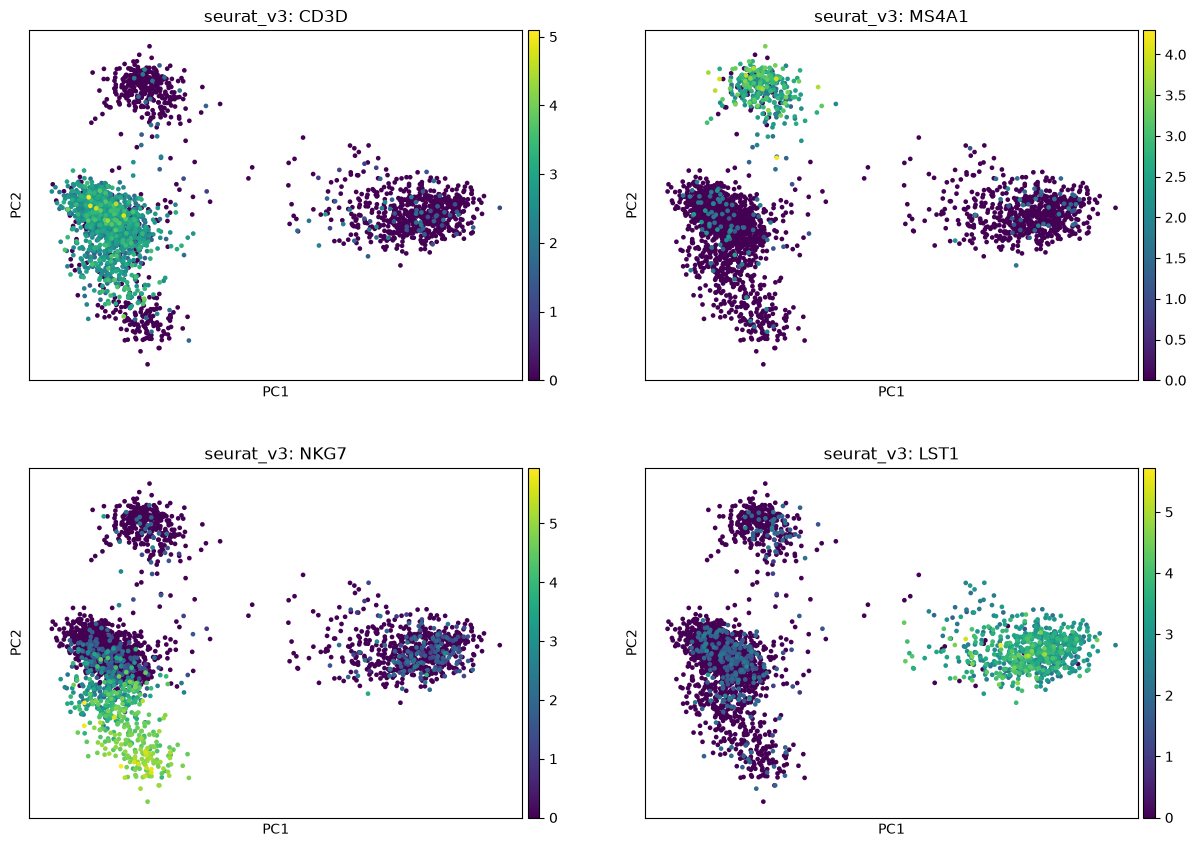

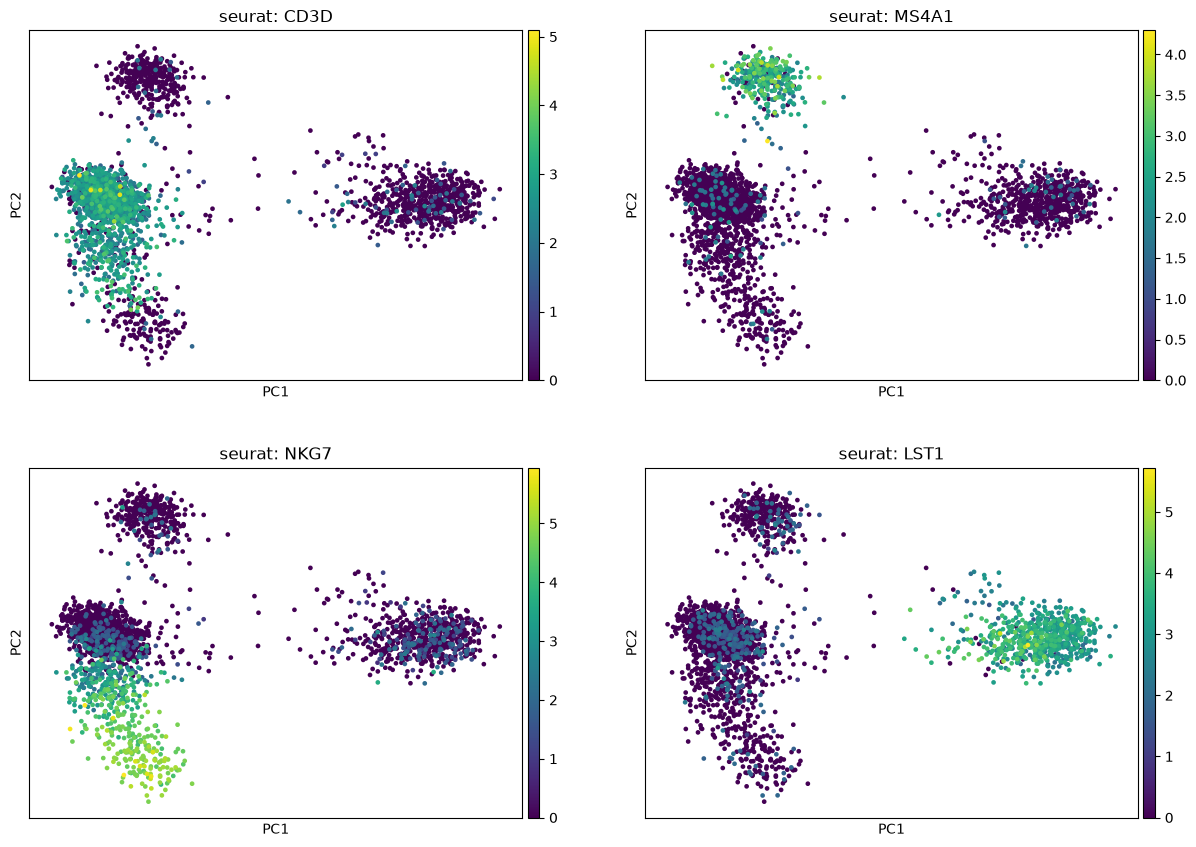

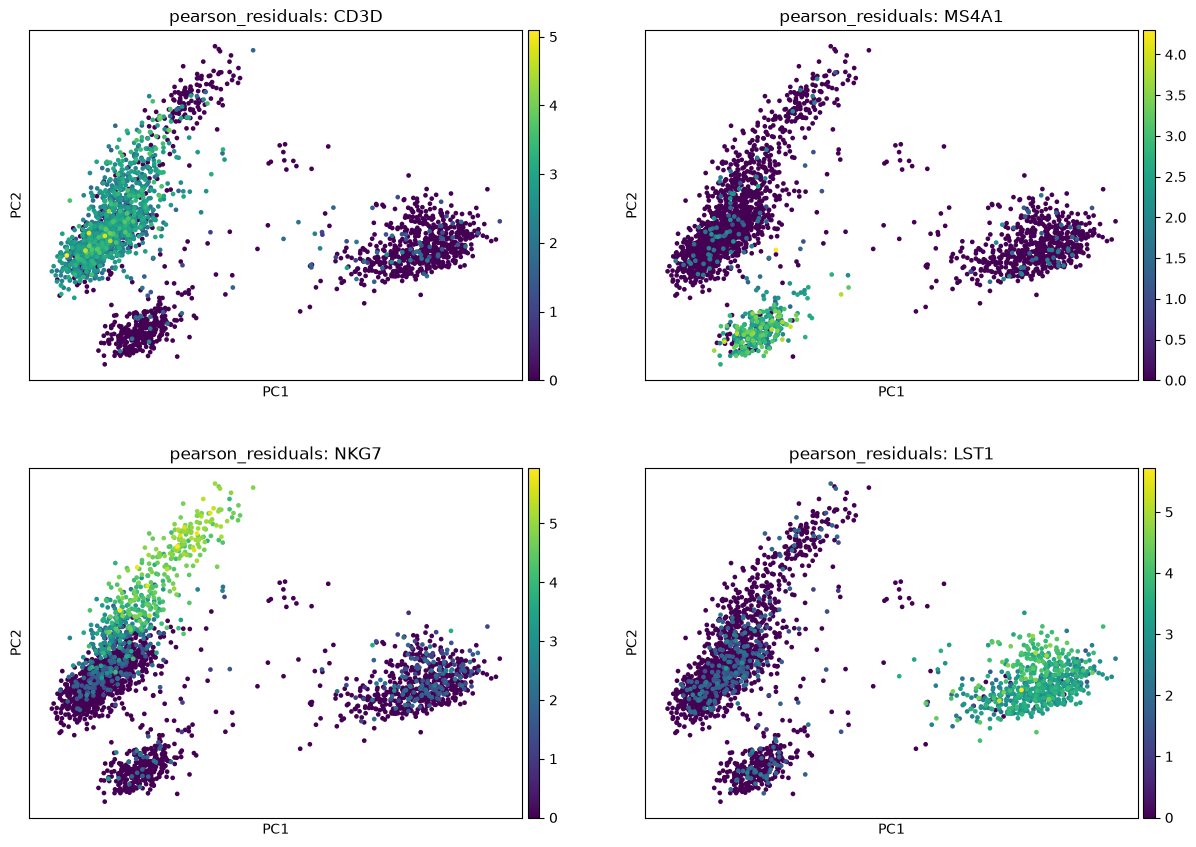

In [31]:
# PCA на генах, отобранных каждым методом (нормализованная/логарифмированная
# матрица для всех трёх одна и та же — она не пересчитывалась)
for ad in (adata_v3, adata_seurat, adata_pr):
    sc.tl.pca(ad, mask_var="highly_variable")

sc.pl.pca(
    adata_v3, color=marker_genes, ncols=2,
    title=[f"seurat_v3: {g}" for g in marker_genes],
)
sc.pl.pca(
    adata_seurat, color=marker_genes, ncols=2,
    title=[f"seurat: {g}" for g in marker_genes],
)
sc.pl.pca(
    adata_pr, color=marker_genes, ncols=2,
    title=[f"pearson_residuals: {g}" for g in marker_genes],
)

**Ответы.**

Взаимное расположение клеток обычно получается похожим (крупные оси вариации,
связанные с основными иммунными популяциями, видны при любом разумном отборе
HVG), но не идентичным — точные координаты и то, какая именно компонента
сильнее разделяет ту или иную популяцию, могут немного отличаться между
методами.

Группы клеток с характерной экспрессией маркеров (`CD3D`, `MS4A1`, `NKG7`,
`LST1`), как правило, сохраняются во всех трёх вариантах PCA: это самые
заметные источники биологической вариации в PBMC, и они обычно оказываются
высоковариабельными при любом разумном способе отбора HVG — устойчивость к
выбору метода и есть один из признаков того, что сигнал реальный, а не
артефакт конкретного алгоритма.

Пересечение наборов HVG обычно заметное, но неполное — точное число выведено
кодом выше. Так и должно быть: `seurat_v3` оценивает вариабельность через
регрессию дисперсии от среднего на сырых counts (vst), классический `seurat`
работает с биннингом по среднему/дисперсии на уже прологарифмированных данных,
а `pearson_residuals` использует ещё одну статистическую модель (отрицательное
биномиальное распределение с общей overdispersion `theta`). Разные
математические модели шума закономерно дают немного разные списки, особенно
на границе отсечки "топ-N генов".

## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


### Решение

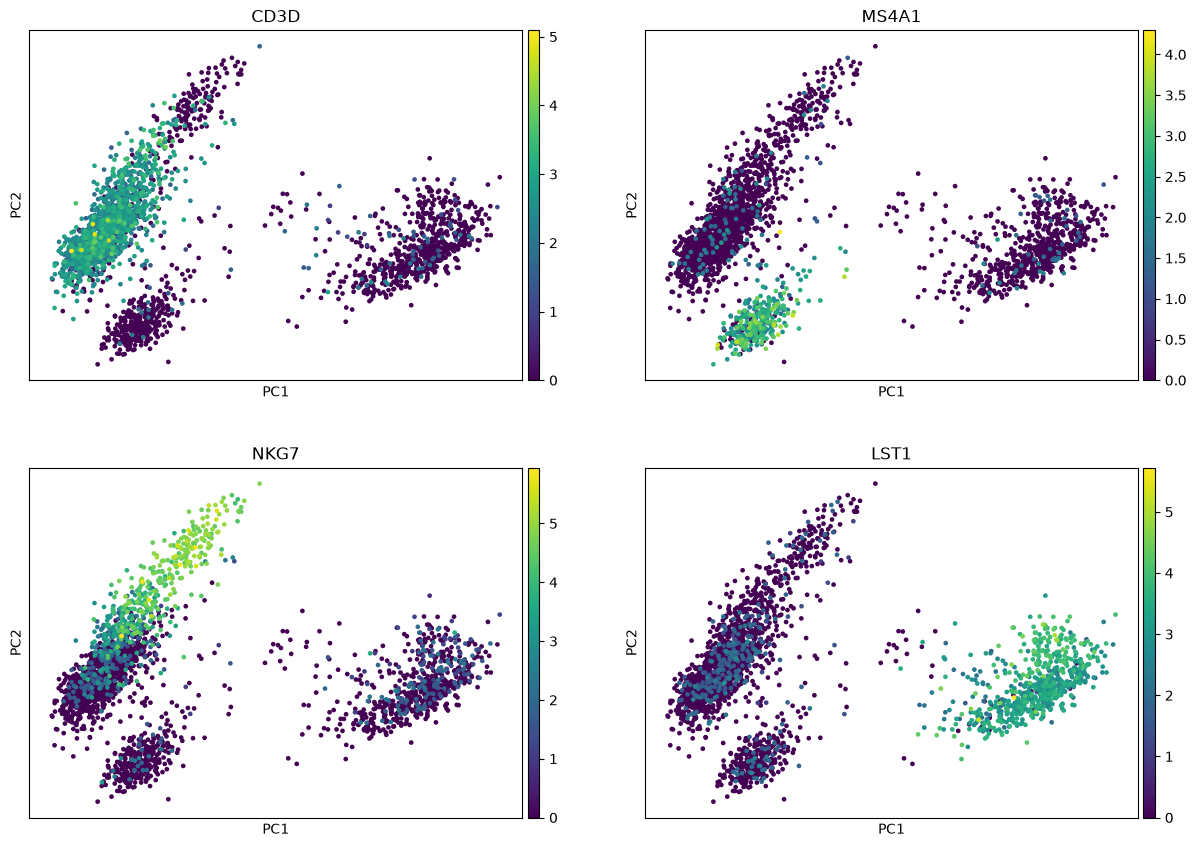

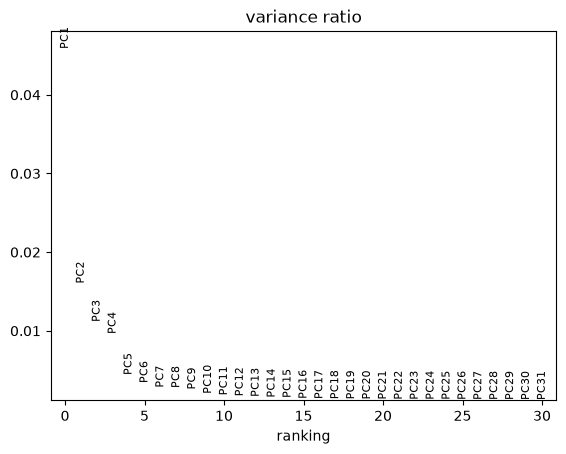

In [32]:
marker_genes = ["CD3D", "MS4A1", "NKG7", "LST1"]

# PCA по всем генам, прошедшим QC, без ограничения набором HVG
adata_allgenes = adata_base.copy()
sc.tl.pca(adata_allgenes, mask_var=None)

sc.pl.pca(adata_allgenes, color=marker_genes, ncols=2)
sc.pl.pca_variance_ratio(adata_allgenes, n_pcs=30)

In [33]:
print("Доля объяснённой дисперсии, PCA по 2000 HVG (первые 5 PC):")
print(adata_base.uns["pca"]["variance_ratio"][:5])
print()
print("Доля объяснённой дисперсии, PCA по всем генам (первые 5 PC):")
print(adata_allgenes.uns["pca"]["variance_ratio"][:5])

Доля объяснённой дисперсии, PCA по 2000 HVG (первые 5 PC):
[0.09977637 0.03281635 0.02261196 0.01190042 0.00719322]

Доля объяснённой дисперсии, PCA по всем генам (первые 5 PC):
[0.04583399 0.01600766 0.01112789 0.00959635 0.00438161]


**Ответы.**

Структура клеток на PCA при использовании всех генов обычно выглядит более
"размытой", с менее чётким разделением знакомых популяций: множество генов, чья
вариация — преимущественно шум (пуассоновский шум счётчиков при низкой
экспрессии), снижают относительный вклад тех немногих генов, которые реально
разделяют клеточные популяции.

Доля объяснённой дисперсии первых компонент (значения выведены кодом выше),
как правило, заметно ниже при PCA по всем генам, чем при PCA по 2000 HVG — это
прямое следствие того, что общая дисперсия "размазана" по гораздо большему
числу признаков, многие из которых не несут биологического сигнала.

Использование всех доступных генов не обязательно делает PCA информативнее,
потому что PCA максимизирует *суммарную* объяснённую дисперсию без разбора,
полезна она или нет: гены с высокой, но в основном шумовой изменчивостью
(например, из-за низкой общей экспрессии) "перетягивают" на себя часть
дисперсии и смещают главные оси в сторону направлений, которые не обязательно
соответствуют реальной биологической структуре. Отбор HVG — это способ заранее
убрать такие гены и сосредоточить PCA на той части вариации, которая
действительно различает клетки.

## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


### Решение

In [34]:
import pandas as pd

# Средняя экспрессия и дисперсия по исходным (сырым) counts, посчитанным
# ДО нормализации/логарифмирования — они лежат в layers["counts"]
counts = adata_base.layers["counts"]

mean_umi = np.asarray(counts.mean(axis=0)).ravel()
var_umi = np.asarray(counts.power(2).mean(axis=0)).ravel() - mean_umi ** 2

adata_base.var["mean_umi_per_cell"] = mean_umi
adata_base.var["var_umi_per_cell"] = var_umi

hvg_mask = adata_base.var["highly_variable"]

top_hvg = (
    adata_base.var.loc[hvg_mask]
    .sort_values("mean_umi_per_cell", ascending=False)
    .head(50)
)
top_non_hvg = (
    adata_base.var.loc[~hvg_mask]
    .sort_values("mean_umi_per_cell", ascending=False)
    .head(50)
)

print("Топ-50 HVG по среднему числу UMI на клетку:")
display(top_hvg[["mean_umi_per_cell", "var_umi_per_cell"]])

print("Топ-50 не-HVG по среднему числу UMI на клетку:")
display(top_non_hvg[["mean_umi_per_cell", "var_umi_per_cell"]])

Топ-50 HVG по среднему числу UMI на клетку:


,mean_umi_per_cell,var_umi_per_cell
MALAT1,60.036770,1066.560791
TMSB4X,46.140259,883.347900
B2M,45.289234,659.146484
FTL,27.999622,2041.860962
FTH1,21.535631,1224.501953
ACTB,17.458681,334.393127
LYZ,10.408263,575.141479
CD74,8.579606,261.794067
S100A4,7.343063,86.245087
MT-CO2,6.888553,56.958008


Топ-50 не-HVG по среднему числу UMI на клетку:


,mean_umi_per_cell,var_umi_per_cell
RPL10,33.017437,307.451660
RPL13,28.774073,280.544189
RPL13A,28.644428,264.611938
RPS2,24.092115,222.750793
RPS6,23.293026,217.956970
RPS18,20.609552,166.665588
RPL11,19.285824,128.374695
RPL32,19.239576,122.023712
RPS3,19.013647,146.745056
RPL19,18.272554,149.695648


In [35]:
print("Средняя экспрессия, HVG (топ-50):", top_hvg["mean_umi_per_cell"].mean())
print("Средняя экспрессия, не-HVG (топ-50):", top_non_hvg["mean_umi_per_cell"].mean())
print("Средняя дисперсия, HVG (топ-50):", top_hvg["var_umi_per_cell"].mean())
print("Средняя дисперсия, не-HVG (топ-50):", top_non_hvg["var_umi_per_cell"].mean())

Средняя экспрессия, HVG (топ-50): 7.1490145
Средняя экспрессия, не-HVG (топ-50): 14.331547
Средняя дисперсия, HVG (топ-50): 173.14291
Средняя дисперсия, не-HVG (топ-50): 94.366135


**Ответы.**

HVG не обязаны быть самыми экспрессируемыми генами: методы отбора HVG
оценивают не абсолютный уровень экспрессии, а *вариабельность относительно
того, что ожидалось бы просто из-за уровня экспрессии* (по модели шума
счётчиков — пуассоновской или отрицательной биномиальной). Ген может быть
экспрессирован очень сильно, но при этом почти одинаково во всех клетках
(классический пример — housekeeping-гены и многие рибосомные белки): такая
низкая *относительная* дисперсия не делает его "variable", сколько бы UMI он
ни давал в абсолютных числах.

Среди самых высокоэкспрессируемых генов, не попавших в HVG, часто оказываются
именно рибосомные белки (`RPS*`/`RPL*`), некоторые митохондриальные гены и
другие активно и равномерно экспрессируемые housekeeping-гены — они хороший
пример того, как высокая экспрессия не означает высокую биологическую
информативность конкретно для разделения клеточных типов.

## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` — общее число UMI клетки.
2. `n_genes_by_counts` — число обнаруженных генов.
3. `pct_counts_mt` — доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X — `total_counts`
- Y — `n_genes_by_counts`
- цвет — `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

### Решение

In [36]:
def load_raw_with_qc():
    ad = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
    ad.var["mt"] = ad.var_names.str.startswith("MT-")
    ad.var["ribo"] = ad.var_names.str.startswith(("RPS", "RPL"))
    sc.pp.calculate_qc_metrics(
        ad, qc_vars=["mt", "ribo"], percent_top=None, inplace=True
    )
    return ad


def run_pipeline(ad, do_qc, do_hvg, n_top_genes=2000):
    ad = ad.copy()
    if do_qc:
        sc.pp.filter_cells(ad, min_genes=200)
        sc.pp.filter_genes(ad, min_cells=3)
        ad = ad[
            (ad.obs.n_genes_by_counts < 2500) & (ad.obs.pct_counts_mt < 5)
        ].copy()
    ad.layers["counts"] = ad.X.copy()
    if do_hvg:
        sc.pp.highly_variable_genes(
            ad, layer="counts", flavor="seurat_v3", n_top_genes=n_top_genes
        )
    sc.pp.normalize_total(ad, target_sum=1e4)
    sc.pp.log1p(ad)
    sc.tl.pca(ad, mask_var="highly_variable" if do_hvg else None)
    return ad


raw5 = load_raw_with_qc()

# 4 комбинации: без/с QC-фильтрацией x без/с отбором HVG.
# Комбинация "без QC, с HVG" — это и есть вариант из последней фразы задания
# ("повторите анализ не используя фильтрацию и QC, но используя HVG").
variants = {
    "без QC, без HVG": run_pipeline(raw5, do_qc=False, do_hvg=False),
    "без QC, с HVG": run_pipeline(raw5, do_qc=False, do_hvg=True),
    "с QC, без HVG": run_pipeline(raw5, do_qc=True, do_hvg=False),
    "с QC, с HVG": run_pipeline(raw5, do_qc=True, do_hvg=True),
}
for name, ad in variants.items():
    print(f"{name}: {ad.shape[0]} клеток, {ad.shape[1]} генов")

без QC, без HVG: 2700 клеток, 32738 генов
без QC, с HVG: 2700 клеток, 32738 генов
с QC, без HVG: 2638 клеток, 13714 генов
с QC, с HVG: 2638 клеток, 13714 генов


--- без QC, без HVG ---


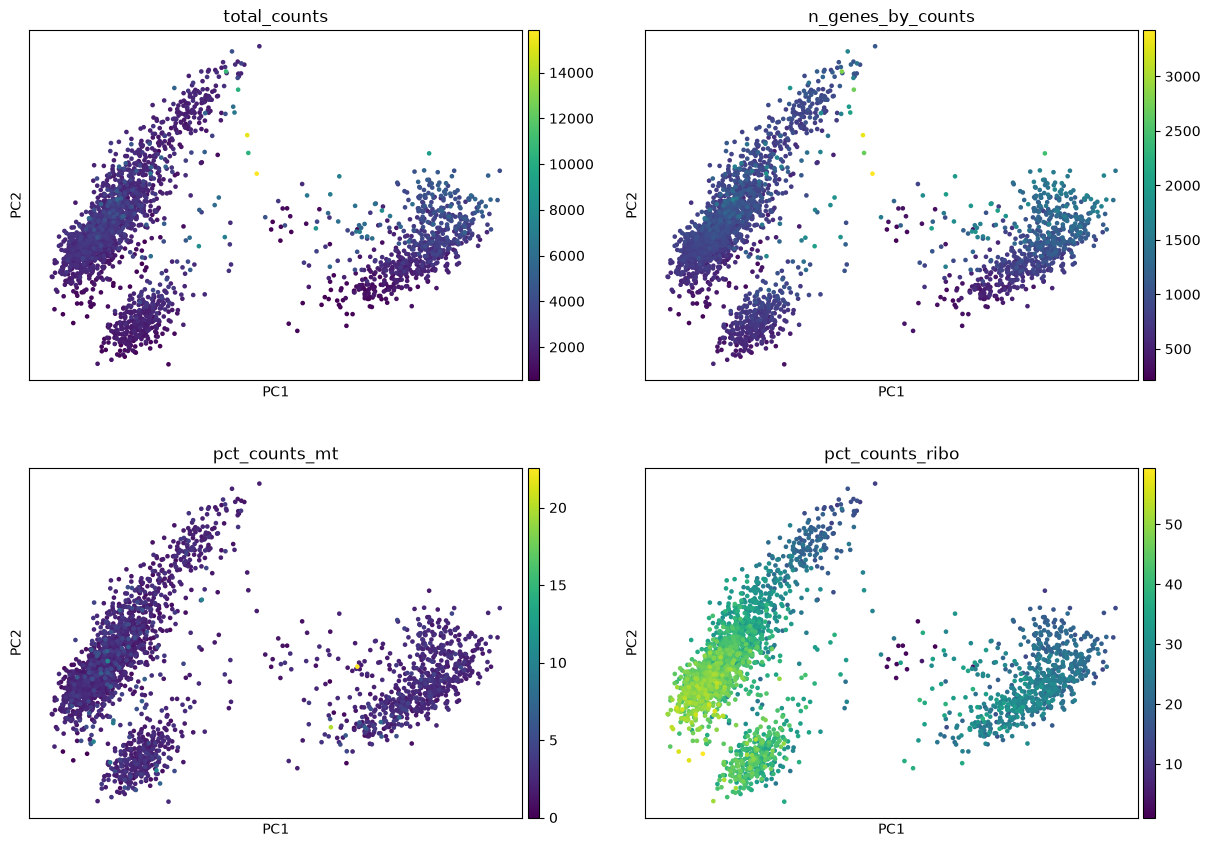

--- без QC, с HVG ---


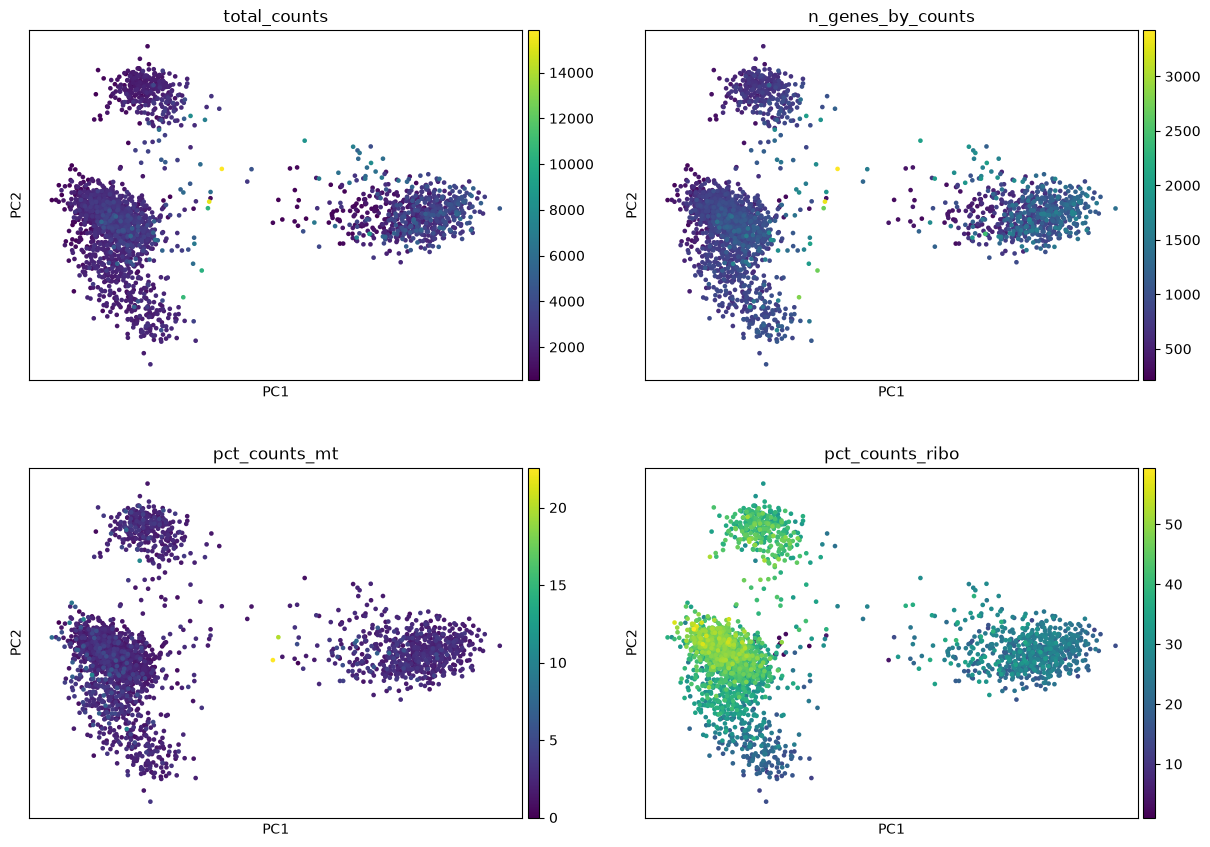

--- с QC, без HVG ---


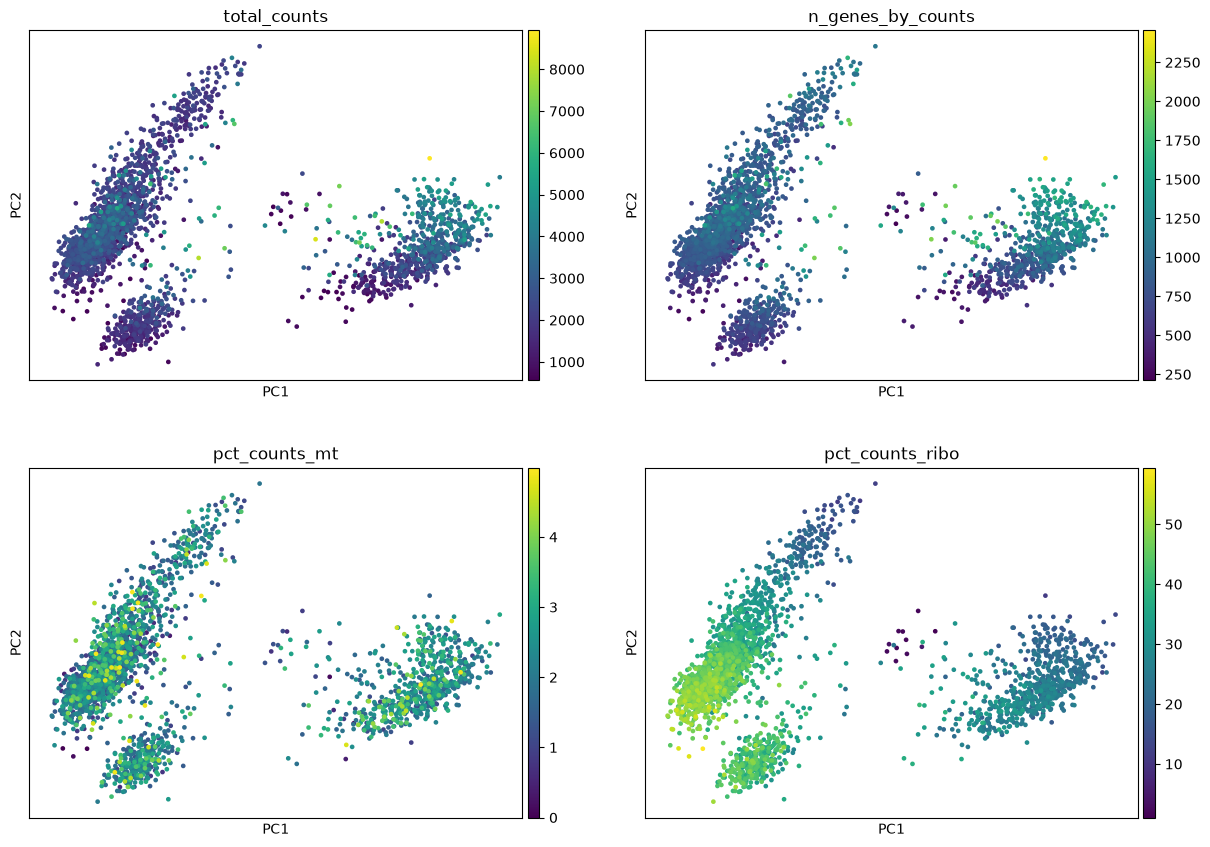

--- с QC, с HVG ---


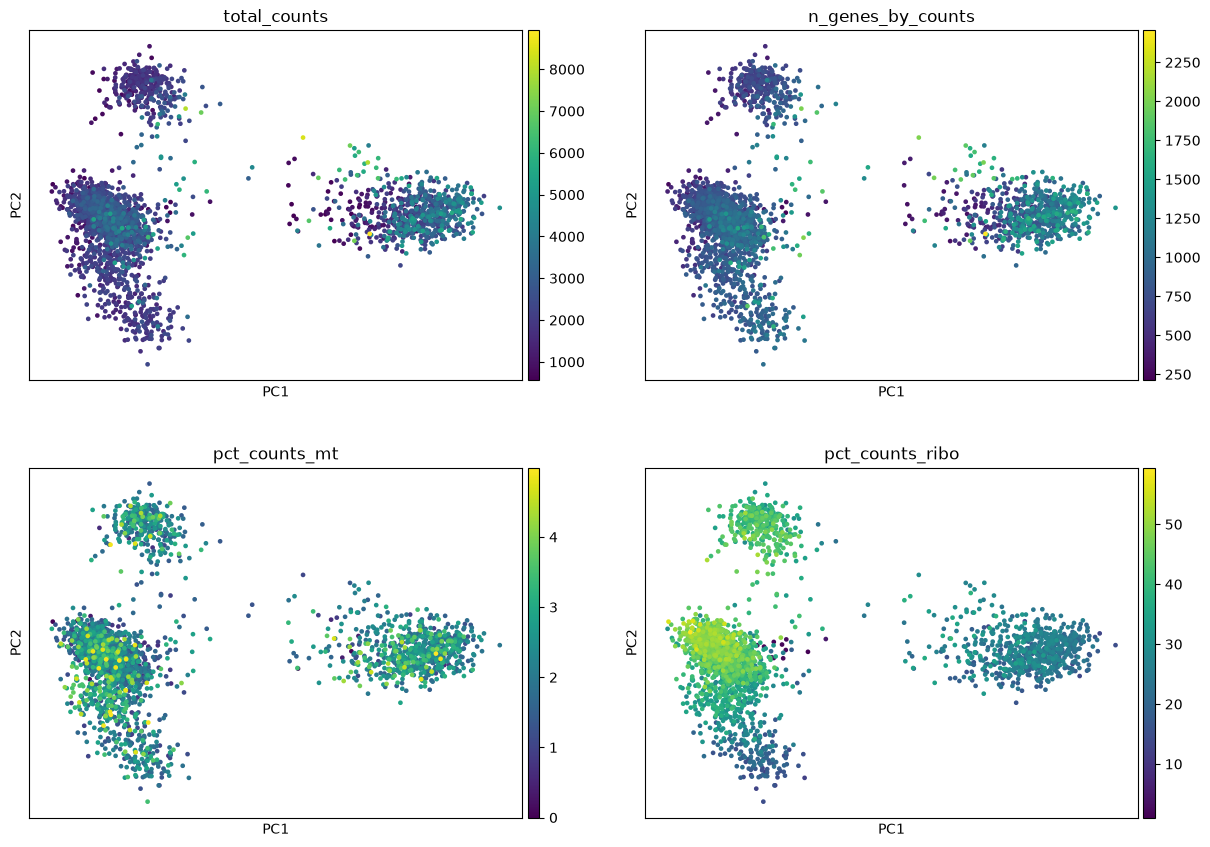

In [37]:
color_vars = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]

for name, ad in variants.items():
    print(f"--- {name} ---")
    sc.pl.pca(ad, color=color_vars, ncols=2)

--- без QC, без HVG ---


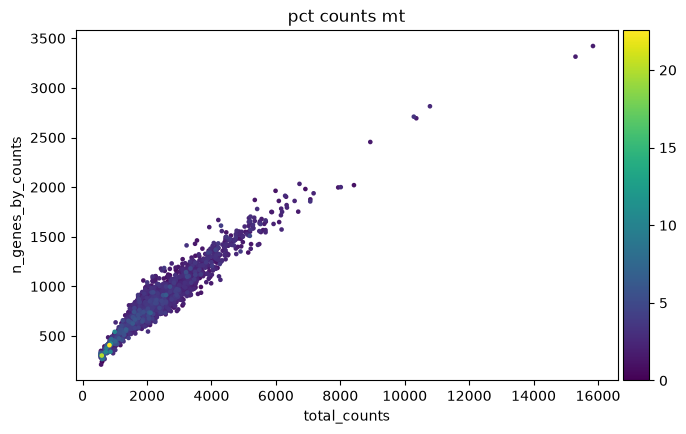

--- без QC, с HVG ---


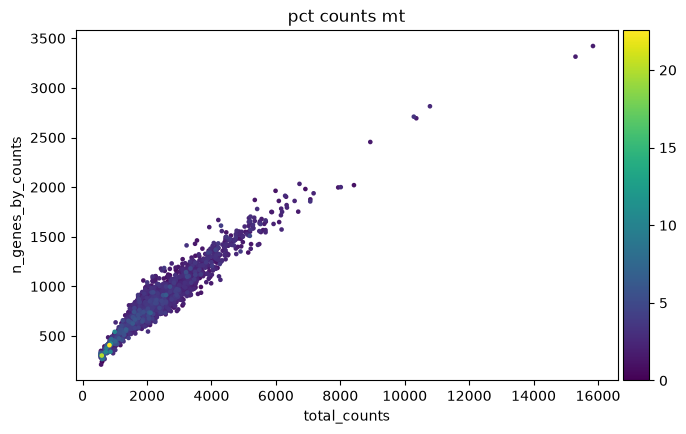

--- с QC, без HVG ---


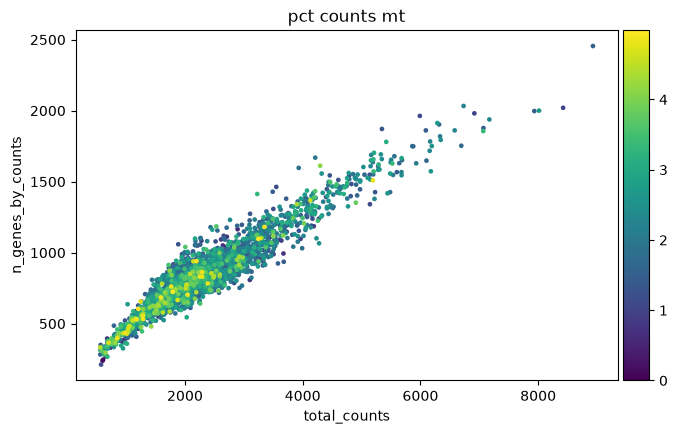

--- с QC, с HVG ---


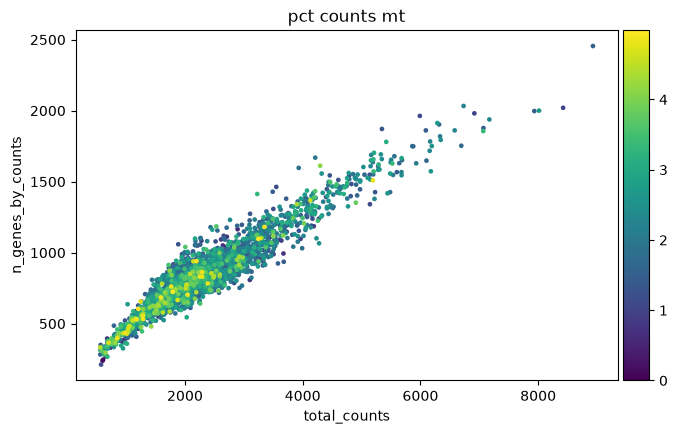

In [38]:
for name, ad in variants.items():
    print(f"--- {name} ---")
    sc.pl.scatter(ad, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

**Ответы.**

Без QC-фильтрации положение клеток на PCA обычно заметно связано с
`total_counts` и `n_genes_by_counts` — градиент глубины секвенирования нередко
ложится вдоль одной из первых компонент, особенно когда в данных ещё остались
низкокачественные клетки с очень малым или аномально большим числом UMI. После
фильтрации по QC эта связь, как правило, ослабевает, хотя полностью не
обязательно исчезает — глубина секвенирования всё ещё может быть частично
скоррелирована с типом клетки (например, более крупные/активные клетки дают
больше UMI).

Направления с повышенной `pct_counts_mt` заметнее всего обычно видны именно в
вариантах "без QC": клетки с высокой долей митохондриальных транскриптов
(потенциально повреждённые) могут образовывать отдельное "облако" или хвост на
графике PCA, который сильно уменьшается или исчезает после фильтрации.

Да — такие паттерны (когда структура на PCA объясняется прежде всего
`total_counts`/`n_genes_by_counts`/`pct_counts_mt`, а не ожидаемыми
биологическими группами) являются типичным признаком того, что на главные
компоненты влияют технические факторы, а не только биология. Именно поэтому
QC-фильтрацию и нормализацию делают *до* PCA — чтобы технический шум не
конкурировал с биологическим сигналом за "место" в первых компонентах.


## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

### Решение

In [39]:
import pandas as pd

hvg_mask = adata_base.var["highly_variable"].to_numpy()
loadings = adata_base.varm["PCs"]  # гены x компоненты; для не-HVG генов = 0,
                                    # так как PCA считался с mask_var="highly_variable"

pc1 = pd.Series(loadings[hvg_mask, 0], index=adata_base.var_names[hvg_mask])
pc2 = pd.Series(loadings[hvg_mask, 1], index=adata_base.var_names[hvg_mask])

top_pos_pc1 = pc1.sort_values(ascending=False).head(10)
top_neg_pc1 = pc1.sort_values(ascending=True).head(10)
top_pos_pc2 = pc2.sort_values(ascending=False).head(10)
top_neg_pc2 = pc2.sort_values(ascending=True).head(10)

print("PC1, топ-10 положительных loadings:")
print(top_pos_pc1)
print("\nPC1, топ-10 отрицательных loadings:")
print(top_neg_pc1)
print("\nPC2, топ-10 положительных loadings:")
print(top_pos_pc2)
print("\nPC2, топ-10 отрицательных loadings:")
print(top_neg_pc2)

PC1, топ-10 положительных loadings:
LYZ       0.220199
CST3      0.212370
S100A9    0.210871
TYROBP    0.199072
S100A8    0.170560
LGALS1    0.168186
AIF1      0.166196
LST1      0.165629
FCER1G    0.156248
FCN1      0.150878
dtype: float64

PC1, топ-10 отрицательных loadings:
LTB      -0.112827
IL32     -0.106143
MALAT1   -0.067260
IL7R     -0.059417
CCL5     -0.051053
CD2      -0.045544
CTSW     -0.043735
STK17A   -0.037906
ACAP1    -0.036313
CD247    -0.036139
dtype: float64

PC2, топ-10 положительных loadings:
HLA-DRA     0.267638
CD74        0.209743
HLA-DPB1    0.197692
HLA-DRB1    0.192726
CD79A       0.183641
HLA-DPA1    0.180487
HLA-DQA1    0.169166
HLA-DQB1    0.160824
CD79B       0.157984
HLA-DRB5    0.142120
dtype: float64

PC2, топ-10 отрицательных loadings:
NKG7     -0.216003
S100A4   -0.180781
CCL5     -0.165346
IL32     -0.144602
GNLY     -0.134453
CTSW     -0.134233
GZMA     -0.134096
CST7     -0.131238
SRGN     -0.123198
ANXA1    -0.120073
dtype: float64


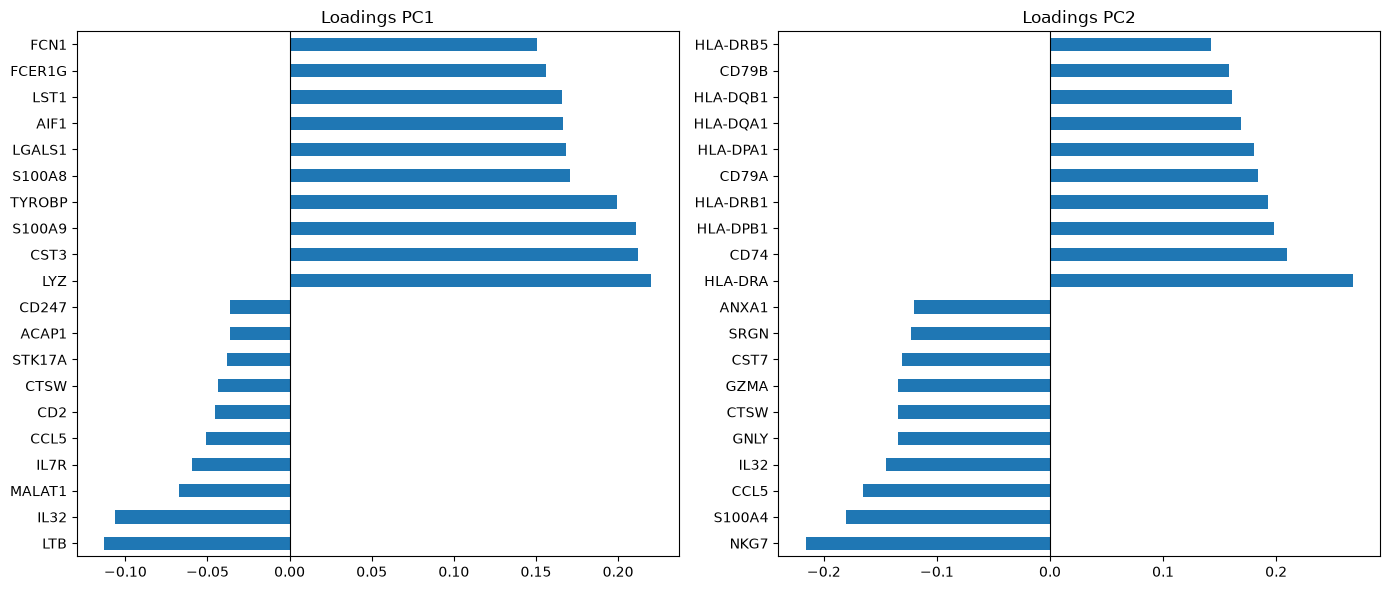

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

pd.concat([top_neg_pc1, top_pos_pc1]).plot.barh(ax=axes[0])
axes[0].set_title("Loadings PC1")
axes[0].axvline(0, color="black", linewidth=0.8)

pd.concat([top_neg_pc2, top_pos_pc2]).plot.barh(ax=axes[1])
axes[1].set_title("Loadings PC2")
axes[1].axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

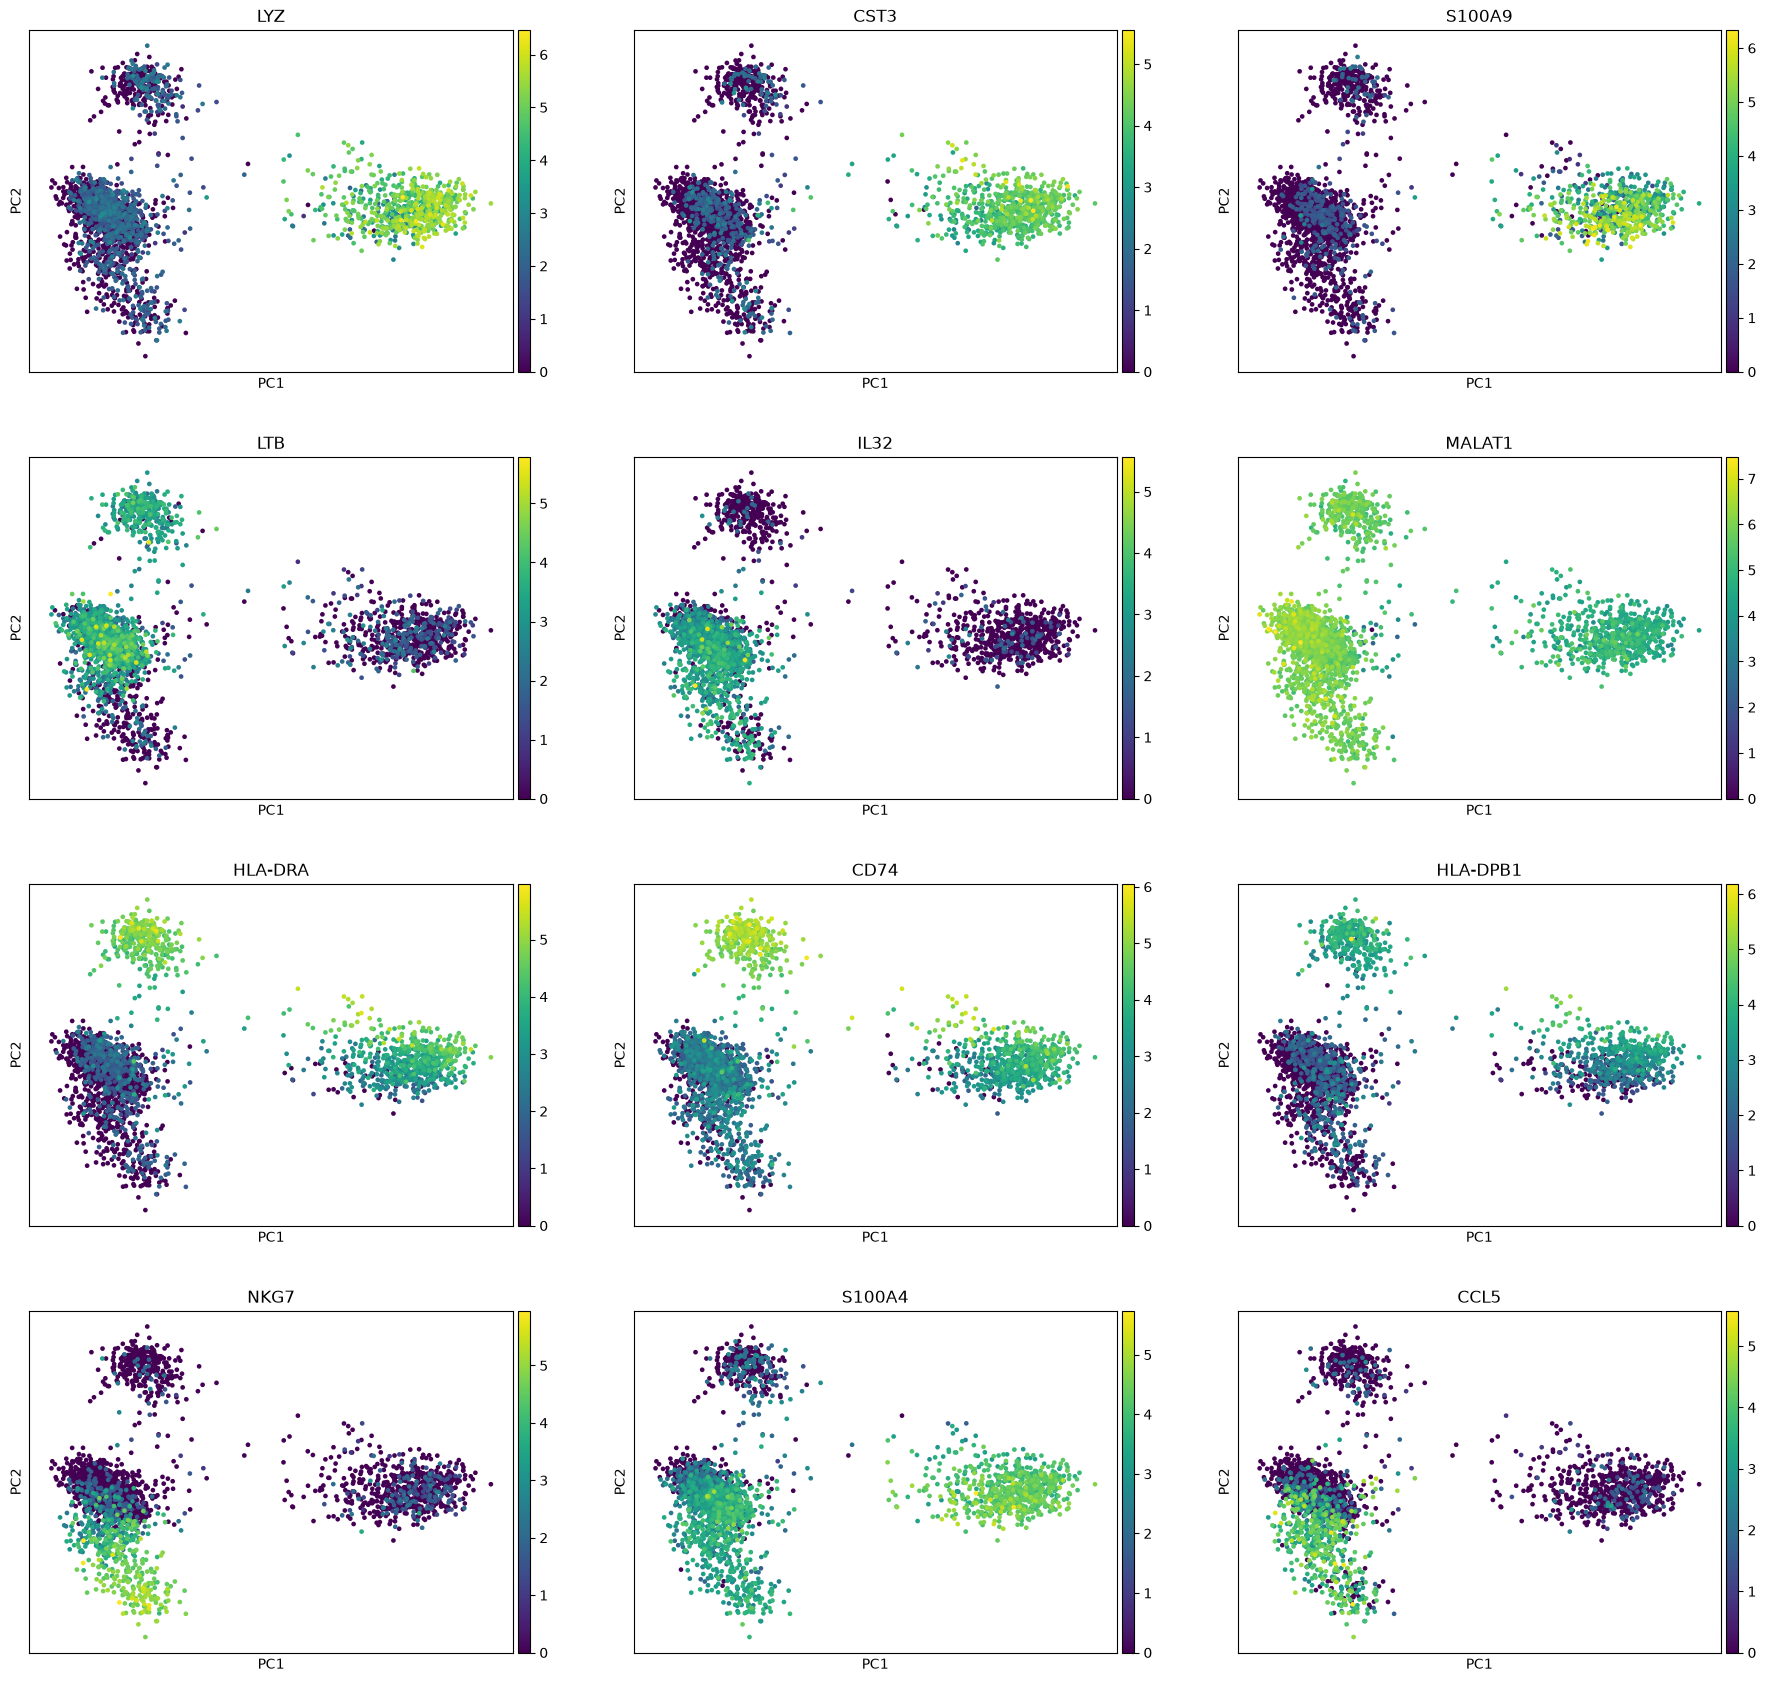

In [41]:
genes_to_show = (
    list(top_pos_pc1.index[:3])
    + list(top_neg_pc1.index[:3])
    + list(top_pos_pc2.index[:3])
    + list(top_neg_pc2.index[:3])
)
genes_to_show = list(dict.fromkeys(genes_to_show))  # убираем дубликаты, сохраняя порядок

sc.pl.pca(adata_base, color=genes_to_show, ncols=3)

**Ответы.**

Конкретные гены с наибольшими по модулю loadings для PC1 и PC2 — это гены,
напечатанные кодом выше; имеет смысл свериться по ним с базами вроде NCBI
Gene/GeneCards или с собственными биологическими знаниями. На практике для
PBMC среди генов с большими loadings почти всегда оказываются гены двух типов:
(а) маркеры конкретных иммунных популяций (T/NK/B-клеточные или
моноцитарные гены) — именно они формируют основное разделение клеток по типу,
и (б) гены клеточного цикла (например, из наборов S/G2M-фаз) или QC-связанные
гены (митохондриальные/рибосомные), если они не были полностью убраны на
этапе QC/HVG.

Если среди топовых loadings конкретной компоненты преобладают иммунные
маркеры — её можно интерпретировать как ось "тип клетки"; если преобладают
гены клеточного цикла — компонента, скорее всего, отражает пролиферативный
статус клетки, а не её тип. Такая интерпретация всегда ограничена: PCA даёт
линейные комбинации множества генов, и один и тот же биологический процесс
нередко "размазывается" сразу по нескольким компонентам, а не сосредоточен
строго в одной.

## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток. 

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

### Решение

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


--- без log1p ---


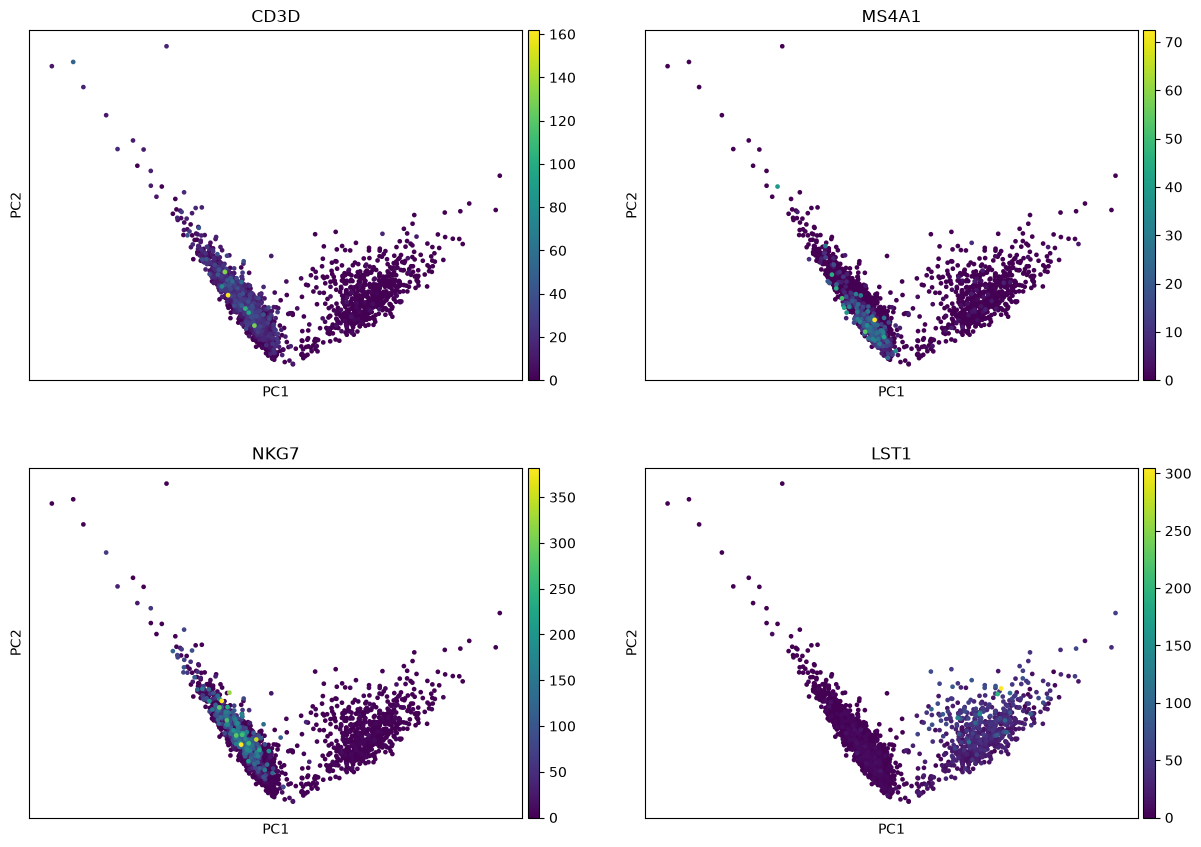

--- без нормализации и без log1p ---


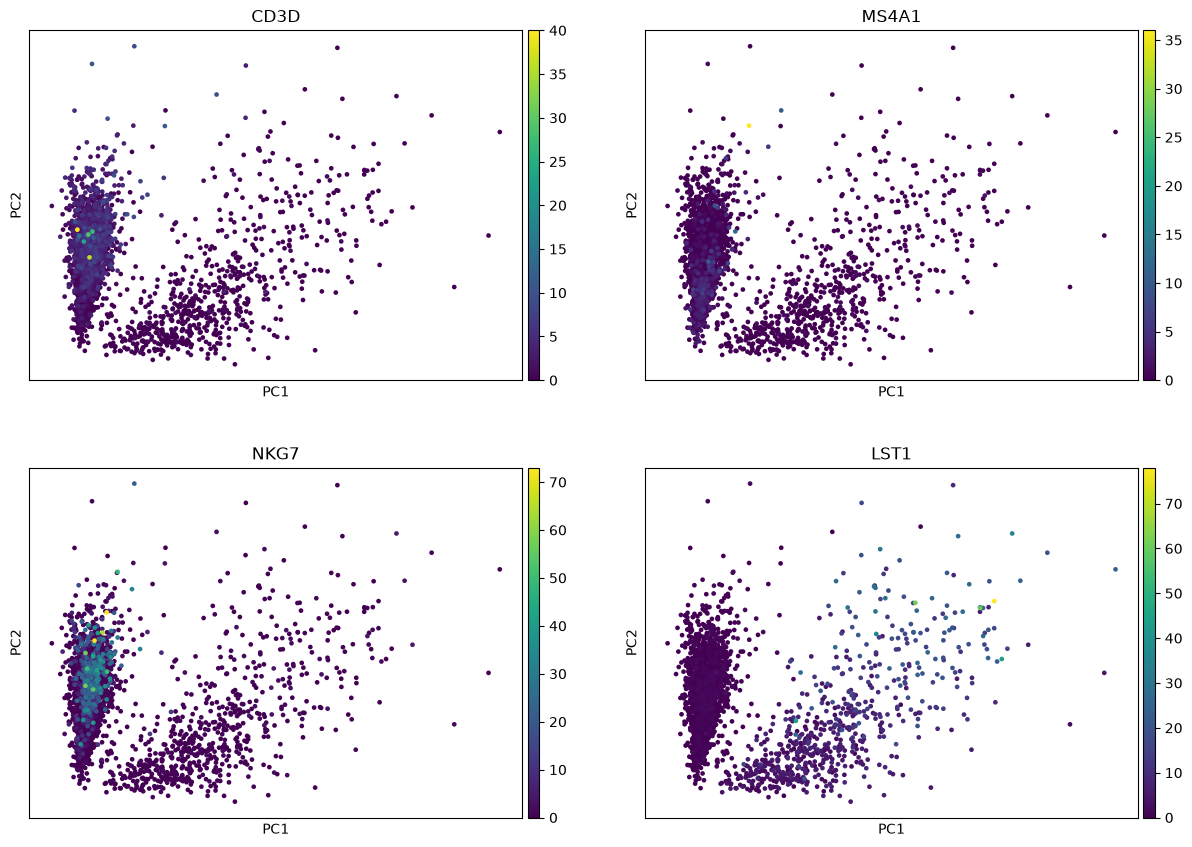

--- нормализация + log1p + scale ---


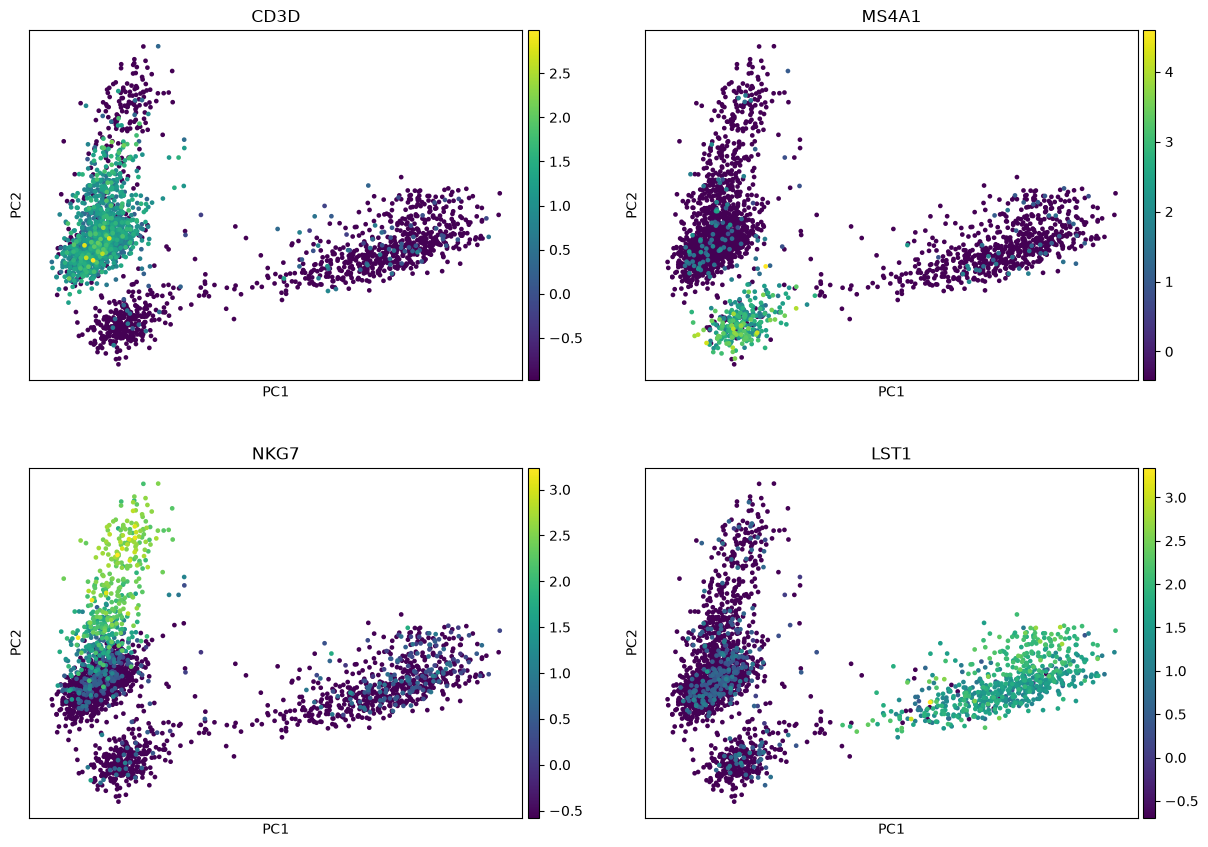

In [42]:
def load_qc_filtered_with_counts():
    ad = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
    ad.var["mt"] = ad.var_names.str.startswith("MT-")
    sc.pp.calculate_qc_metrics(ad, qc_vars=["mt"], percent_top=None, inplace=True)
    sc.pp.filter_cells(ad, min_genes=200)
    sc.pp.filter_genes(ad, min_cells=3)
    ad = ad[(ad.obs.n_genes_by_counts < 2500) & (ad.obs.pct_counts_mt < 5)].copy()
    ad.layers["counts"] = ad.X.copy()
    sc.pp.highly_variable_genes(
        ad, layer="counts", flavor="seurat_v3", n_top_genes=2000
    )
    return ad


marker_genes = ["CD3D", "MS4A1", "NKG7", "LST1"]
base7 = load_qc_filtered_with_counts()

# 1) нормализация без log1p
adata_nolog = base7.copy()
sc.pp.normalize_total(adata_nolog, target_sum=1e4)
sc.tl.pca(adata_nolog, mask_var="highly_variable")

# 2) ни нормализации, ни log1p — сырые counts напрямую в PCA
adata_raw_counts = base7.copy()
sc.tl.pca(adata_raw_counts, mask_var="highly_variable")

# 3) нормализация + log1p + scale
adata_scaled = base7.copy()
sc.pp.normalize_total(adata_scaled, target_sum=1e4)
sc.pp.log1p(adata_scaled)
sc.pp.scale(adata_scaled, max_value=10)
sc.tl.pca(adata_scaled, mask_var="highly_variable")

for name, ad in [
    ("без log1p", adata_nolog),
    ("без нормализации и без log1p", adata_raw_counts),
    ("нормализация + log1p + scale", adata_scaled),
]:
    print(f"--- {name} ---")
    sc.pl.pca(ad, color=marker_genes, ncols=2)

**Ответы.**

Сильнее всего на PCA влияет логарифмирование. Без `log1p` распределение
экспрессии остаётся сильно скошенным (несколько генов с очень большими
абсолютными значениями счётчиков доминируют над суммарной дисперсией), поэтому
PCA в основном отражает различия в общей глубине секвенирования и в
нескольких самых "ярких" генах, а не полноценную биологическую структуру
клеток — биологически осмысленное разделение популяций на графиках обычно
выражено заметно слабее, чем на исходном PCA занятия.

Нормализация (`normalize_total`) важна прежде всего для того, чтобы убрать
технический эффект разной глубины секвенирования между клетками: без неё
клетки с большим числом UMI будут выглядеть иначе просто из-за глубины, а не
из-за биологии.

`sc.pp.scale()` обычно даёт более умеренный, "выравнивающий" эффект: она
приводит все гены к единой шкале (среднее 0, дисперсия 1), из-за чего гены с
низкой, но стабильной экспрессией получают больший относительный вес —
основная структура популяций на PCA, как правило, сохраняется, но может
немного измениться баланс вклада отдельных генов и компонент.

По сути: логарифмирование и нормализация делают данные пригодными для
линейного метода вроде PCA — убирают сильную гетероскедастичность счётчиков и
эффект глубины секвенирования, тогда как `scale` — это уже более тонкая
настройка весов генов. Она не обязательна: во многих пайплайнах (в том числе в
pipeline занятия) ограничиваются нормализацией и логарифмированием без
`scale`, и это совершенно рабочий вариант.

## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?

### Решение

In [43]:
# Классический набор генов клеточного цикла человека (Tirosh et al., 2015 /
# Regev lab) — 43 гена S-фазы и 54 гена G2/M-фазы. Это стандартный список,
# используемый в большинстве туториалов по scRNA-seq (в т.ч. в самом scanpy).
s_genes = [
    "MCM5", "PCNA", "TYMS", "FEN1", "MCM2", "MCM4", "RRM1", "UNG", "GINS2",
    "MCM6", "CDCA7", "DTL", "PRIM1", "UHRF1", "MLF1IP", "HELLS", "RFC2",
    "RPA2", "NASP", "RAD51AP1", "GMNN", "WDR76", "SLBP", "CCNE2", "UBR7",
    "POLD3", "MSH2", "ATAD2", "RAD51", "RRM2", "CDC45", "CDC6", "EXO1",
    "TIPIN", "DSCC1", "BLM", "CASP8AP2", "USP1", "CLSPN", "POLA1", "CHAF1B",
    "BRIP1", "E2F8",
]
g2m_genes = [
    "HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A", "NDC80",
    "CKS2", "NUF2", "CKS1B", "MKI67", "TMPO", "CENPF", "TACC3", "FAM64A",
    "SMC4", "CCNB2", "CKAP2L", "CKAP2", "AURKB", "BUB1", "KIF11", "ANP32E",
    "TUBB4B", "GTSE1", "KIF20B", "HJURP", "CDCA3", "HN1", "CDC20", "TTK",
    "CDC25C", "KIF2C", "RANGAP1", "NCAPD2", "DLGAP5", "CDCA2", "CDCA8",
    "ECT2", "KIF23", "HMMR", "AURKA", "PSRC1", "ANLN", "LBR", "CKAP5",
    "CENPE", "CTCF", "NEK2", "G2E3", "GAS2L3", "CBX5", "CENPA",
]

s_genes_present = [g for g in s_genes if g in adata_base.var_names]
g2m_genes_present = [g for g in g2m_genes if g in adata_base.var_names]
print(f"S-фаза: найдено {len(s_genes_present)} из {len(s_genes)} генов в данных")
print(f"G2/M-фаза: найдено {len(g2m_genes_present)} из {len(g2m_genes)} генов в данных")

S-фаза: найдено 36 из 43 генов в данных
G2/M-фаза: найдено 44 из 54 генов в данных


In [44]:
adata_cc = adata_base.copy()
sc.tl.score_genes_cell_cycle(
    adata_cc, s_genes=s_genes_present, g2m_genes=g2m_genes_present
)
print(adata_cc.obs["phase"].value_counts())
adata_cc.obs[["S_score", "G2M_score", "phase"]].head()

phase
G1     1685
S       866
G2M      87
Name: count, dtype: int64


,S_score,G2M_score,phase
AAACATACAACCAC-1,0.088209,-0.109109,S
AAACATTGAGCTAC-1,-0.037546,-0.136801,G1
AAACATTGATCAGC-1,-0.033735,0.010598,G2M
AAACCGTGCTTCCG-1,0.044898,-0.041958,S
AAACCGTGTATGCG-1,-0.050664,-0.015560,G1


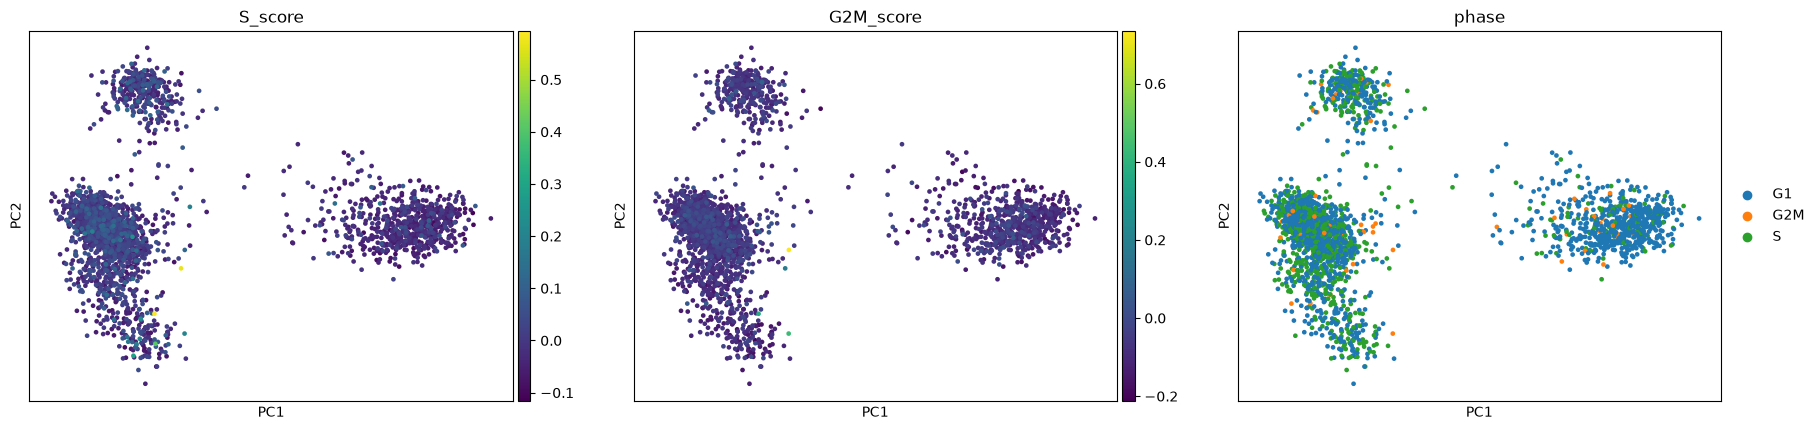

In [45]:
sc.pl.pca(adata_cc, color=["S_score", "G2M_score", "phase"], ncols=3)

**Ответы.**

Клетки могут частично разделяться по фазе клеточного цикла на PCA, но для
спокойных (не активно делящихся) PBMC доля клеток в S/G2M обычно не очень
высока, и этот эффект редко становится доминирующим — чаще он виден как
второстепенный градиент, а не как чёткое разделение на отдельные кластеры.

Связь с PC1/PC2 стоит проверять именно так, как это сделано на графике выше:
если `S_score`/`G2M_score` заметно меняются вдоль одной из первых компонент,
значит, часть вариации, которую PCA "относит" к различиям между клетками, на
самом деле частично объясняется стадией клеточного цикла, а не только
клеточной идентичностью (типом клетки).

Клетки одного типа могут отличаться по экспрессии генов клеточного цикла,
потому что даже внутри одной популяции часть клеток может находиться в
процессе активного деления (например, в ответ на антигенную или митогенную
стимуляцию), тогда как остальные клетки того же типа находятся в состоянии
покоя (G1/G0). То есть клеточный цикл — это отдельный, независимый от типа
клетки источник вариации; при необходимости его вклад можно дополнительно
убрать из данных с помощью `sc.pp.regress_out(adata, ["S_score", "G2M_score"])`
перед дальнейшим анализом (кластеризацией, повторным PCA и т.д.).